# Survival analysis on the *Bone marrow transplant: children* dataset

**Authors:** (add the names of the group here)

In this lab we work with data of pediatric patients with hematologic diseases who received a stem cell transplant. The idea is to see if we can find groups of similar patients and whether these groups have different survival. The steps are:

1. Load the data and do a quick check.
2. Exploratory analysis: missing values, relation of each variable with survival and variables that are correlated.
3. Clustering of the patients (PCA + K-means, and we also try DBSCAN and GMM).
4. Survival of each cluster with Kaplan-Meier and Cox regression, and comparison of both methods.

Dataset: [UCI Repository](https://archive.ics.uci.edu/dataset/565/bone+marrow+transplant+children). `survival_time` is in days and `survival_status` is 1 if the patient died and 0 if the patient was still alive at the end of the follow-up (censored).

## 0. Setup

In [1]:
# !pip install ucimlrepo lifelines scikit-learn pandas numpy matplotlib seaborn scipy
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr
from scipy.stats.contingency import association

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import NearestNeighbors

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test, pairwise_logrank_test, proportional_hazard_test

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# ---- Settings (we can change them here) ----
RANDOM_STATE = 42
K = 3                 # number of clusters (we explain the choice in section 2.1)
P_WEAK = 0.2          # variables with a p-value higher than this are considered "weak"
MIN_LEVEL = 10        # levels with fewer patients than this are merged into "other"
SENTINEL = 1e5        # very big values (like 1,000,000) are codes, not real measurements
MERGE_RARE_COLS = ["Allele", "Antigen"]     # variables where we merge the rare levels
LOG_COLS = ["CD34kgx10d6", "CD3dkgx10d8"]   # cell doses: very skewed, so we use log
SIZE_GROUP = ["Recipientage", "Rbodymass"]   # very correlated (~0.93): they share one weight in the PCA
LOCAL_CSV = Path("data.csv")                # backup file in case the download fails

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
def savefig(name):
    # saves the current figure so we can use it in the report
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

### Load the data

In [2]:
def load_data():
    # first we try to download the data from UCI, if it fails we use the local csv
    try:
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=565)
        X, y = ds.data.features, ds.data.targets
        out = pd.concat([X, y.loc[:, [c for c in y.columns if c not in X.columns]]], axis=1)
        print("Data loaded from the UCI repository.")
    except Exception as e:
        if not LOCAL_CSV.exists():
            raise RuntimeError(f"Could not download the data ({e}). Download data.csv from the UCI page "
                               f"and put it in the same folder as this notebook.")
        out = pd.read_csv(LOCAL_CSV)
        print(f"Data loaded from the local file {LOCAL_CSV}.")
    return out.replace("?", np.nan)

df = load_data()
print(df.shape)

Data loaded from the UCI repository.
(187, 37)


### Variable types

When we load the data, pandas reads almost all the variables as numbers, but in the UCI description many of them are really binary or categorical codes (for example `DonorABO` or `HLAgrI`). If we leave them as numbers, the scaler and the Cox model would treat them as quantities, which does not make sense. For this reason we define the type of each variable by hand:

* **Binary**: variables with values 0/1.
* **Categorical**: variables with more than two levels (we use one-hot encoding later; the ordinal ones like `HLAmatch` are also treated as categories to keep it simple).
* **Numeric**: real quantities like age, body mass or the cell doses.

We also make a list of the **post-transplant variables**, which are only known after (or during) the follow-up.

In [3]:
TIME, EVENT = "survival_time", "survival_status"

BINARY = ["Recipientgender", "Stemcellsource", "Donorage35", "IIIV", "Gendermatch", "RecipientRh", "ABOmatch",
          "DonorCMV", "RecipientCMV", "Riskgroup", "Txpostrelapse", "Diseasegroup", "HLAmismatch",
          "Recipientage10", "Relapse", "aGvHDIIIIV", "extcGvHD"]
CATEGORICAL = ["DonorABO", "RecipientABO", "CMVstatus", "Disease", "HLAmatch", "Antigen", "Allele",
               "HLAgrI", "Recipientageint"]
NUMERIC = ["Donorage", "Recipientage", "Rbodymass", "CD34kgx10d6", "CD3dCD34", "CD3dkgx10d8",
           "ANCrecovery", "PLTrecovery", "time_to_aGvHD_III_IV"]

# Post-transplant variables: we only know them after the transplant, so they do not describe the patient at the start
POST_TX = ["ANCrecovery", "PLTrecovery", "IIIV", "aGvHDIIIIV", "time_to_aGvHD_III_IV",
           "extcGvHD", "Relapse", "Txpostrelapse"]

# check that all the columns are in the data
expected = BINARY + CATEGORICAL + NUMERIC + [TIME, EVENT]
absent = [c for c in expected if c not in df.columns]
assert not absent, f"Columns not found: {absent}. Available: {list(df.columns)}"

def as_label(s):
    # converts a column to text labels ("0", "1", ...) so pandas does not treat it as a number
    conv = pd.to_numeric(s, errors="coerce")
    if conv.notna().sum() == s.notna().sum():
        return conv.map(lambda v: str(int(v)) if pd.notna(v) else np.nan).astype(object)
    return s.map(lambda v: str(v).strip() if pd.notna(v) else np.nan).astype(object)

for c in BINARY + CATEGORICAL:
    df[c] = as_label(df[c])
for c in NUMERIC + [TIME, EVENT]:
    df[c] = pd.to_numeric(df[c], errors="coerce").astype(float)
df[EVENT] = df[EVENT].astype(int)

candidates = BINARY + CATEGORICAL + NUMERIC
print(df[EVENT].value_counts().rename({0: "alive (censored)", 1: "dead"}))
print(f"Censoring rate: {(df[EVENT]==0).mean():.1%} | patients: {len(df)} | events: {df[EVENT].sum()}")

survival_status
alive (censored)    102
dead                 85
Name: count, dtype: int64
Censoring rate: 54.5% | patients: 187 | events: 85


### Quick data check

Before starting we check three things in the data that could cause problems later:

1. In some time columns (recovery times and GvHD) there are patients with a huge value like 1,000,000. It looks like a code for "the event never happened" and not a real time, so we cannot use these columns as normal numbers.
2. Some categorical variables have the code `-1`. We keep it as one more level.
3. Some levels have very few patients, and this gives unstable results in the models.

In [4]:
audit = pd.DataFrame({c: {"min": df[c].min(), "median": df[c].median(), "max": df[c].max(),
                          f"n >= {SENTINEL:.0e}": int((df[c] >= SENTINEL).sum())} for c in NUMERIC}).T
display(audit)
sentinel_cols = [c for c in NUMERIC if (df[c] >= SENTINEL).any()]
print("Numeric columns with huge values:", sentinel_cols)

print("\nNumber of patients in each level of the categorical variables:")
for c in CATEGORICAL:
    print(f"  {c:16s}", df[c].value_counts(dropna=False).to_dict())

rare = {c: [l for l, n in df[c].value_counts().items() if n < MIN_LEVEL] for c in CATEGORICAL}
print("\nLevels with fewer than", MIN_LEVEL, "patients:", {c: l for c, l in rare.items() if l})

,min,median,max,n >= 1e+05
Donorage,18.646575,33.550685,55.553425,0.0
Recipientage,0.600000,9.600000,20.200000,0.0
Rbodymass,6.000000,33.000000,103.400000,0.0
CD34kgx10d6,0.790000,9.720000,57.780000,0.0
CD3dCD34,0.204132,2.734462,99.560970,0.0
CD3dkgx10d8,0.040000,4.325000,20.020000,0.0
ANCrecovery,9.000000,15.000000,1000000.000000,5.0
PLTrecovery,9.000000,21.000000,1000000.000000,17.0
time_to_aGvHD_III_IV,10.000000,1000000.000000,1000000.000000,145.0


Numeric columns with huge values: ['ANCrecovery', 'PLTrecovery', 'time_to_aGvHD_III_IV']

Number of patients in each level of the categorical variables:
  DonorABO         {'0': 73, '1': 71, '-1': 28, '2': 15}
  RecipientABO     {'1': 75, '-1': 50, '0': 48, '2': 13, nan: 1}
  CMVstatus        {'2': 57, '0': 48, '3': 39, '1': 27, nan: 16}
  Disease          {'ALL': 68, 'chronic': 45, 'AML': 33, 'nonmalignant': 32, 'lymphoma': 9}
  HLAmatch         {'0': 94, '1': 65, '2': 23, '3': 5}
  Antigen          {'-1': 93, '1': 65, '0': 21, '2': 7, nan: 1}
  Allele           {'-1': 93, '0': 54, '1': 32, '2': 6, '3': 1, nan: 1}
  HLAgrI           {'0': 94, '1': 42, '4': 19, '2': 14, '3': 9, '7': 5, '5': 4}
  Recipientageint  {'2': 89, '1': 51, '0': 47}

Levels with fewer than 10 patients: {'Disease': ['lymphoma'], 'HLAmatch': ['3'], 'Antigen': ['2'], 'Allele': ['2', '3'], 'HLAgrI': ['3', '7', '5']}


## 1. Exploratory analysis

### 1.1 Missing values

In [5]:
miss = (df[candidates].isna().sum().to_frame("n_missing")
        .assign(pct=lambda d: (100 * d.n_missing / len(df)).round(1),
                post_transplant=lambda d: d.index.isin(POST_TX))
        .query("n_missing > 0").sort_values("n_missing", ascending=False))
display(miss)
print(f"Patients with at least one missing value: {df[candidates].isna().any(axis=1).sum()} of {len(df)}")

,n_missing,pct,post_transplant
extcGvHD,31,16.6,True
CMVstatus,16,8.6,False
RecipientCMV,14,7.5,False
CD3dCD34,5,2.7,False
CD3dkgx10d8,5,2.7,False
RecipientRh,2,1.1,False
DonorCMV,2,1.1,False
Rbodymass,2,1.1,False
ABOmatch,1,0.5,False
RecipientABO,1,0.5,False


Patients with at least one missing value: 45 of 187


There are not many missing values. The biggest one is `extcGvHD`, but it is a post-transplant variable and we will not use it for the clustering. For the other variables we **impute** the missing values (median for numeric and most frequent value for the rest) instead of deleting patients, because we only have 187 patients and we do not want to lose events. The imputation does not use the survival information.

### 1.2 Which variables are related to survival?

We cannot use a normal correlation with `survival_time`, because many times are censored (the patient was still alive) and they are not real survival times. Instead, we fit a **univariate Cox model** for each variable and look at the p-value of the likelihood ratio test. For categorical variables we test the whole variable (all its levels together) and not only one level. In the plot we show -log10(p), so a longer bar means a stronger relation with survival.

,feature,dof,n,p_lr,c_index,post_transplant,has_huge_values
0,PLTrecovery,1,187,0.0000,0.6176,True,True
1,ANCrecovery,1,187,0.0000,0.5426,True,True
2,Rbodymass,1,185,0.0004,0.5947,False,False
3,CD3dkgx10d8,1,182,0.0012,0.6067,False,False
4,Recipientage,1,187,0.0026,0.5979,False,False
5,Relapse,1,187,0.0030,0.5393,True,False
6,extcGvHD,1,156,0.0039,0.5750,True,False
7,CD34kgx10d6,1,187,0.0220,0.5958,False,False
8,Disease,4,187,0.0236,0.5488,False,False
9,Recipientage10,1,187,0.0357,0.5589,False,False


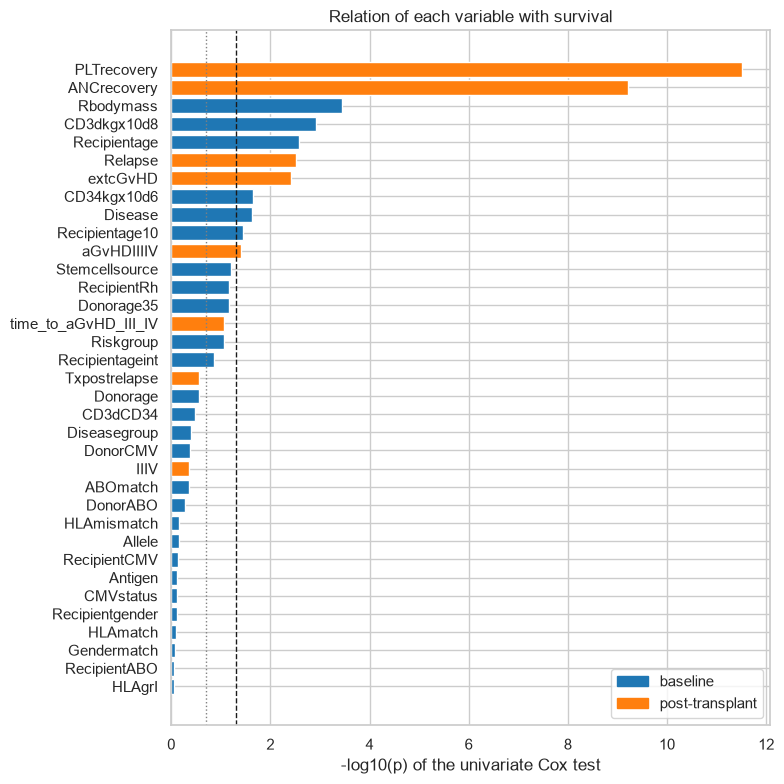

Baseline variables with p > 0.2 (weak): ['Donorage', 'CD3dCD34', 'Diseasegroup', 'DonorCMV', 'ABOmatch', 'DonorABO', 'HLAmismatch', 'Allele', 'RecipientCMV', 'Antigen', 'CMVstatus', 'Recipientgender', 'HLAmatch', 'Gendermatch', 'RecipientABO', 'HLAgrI']


In [6]:
def uni_cox(c):
    # Cox model with only one variable (numeric ones are standardized, categorical ones use dummies)
    x = df[[c, TIME, EVENT]].dropna()
    if c in NUMERIC:
        Xc = pd.DataFrame({c: StandardScaler().fit_transform(x[[c]])[:, 0]}, index=x.index)
    else:
        Xc = pd.get_dummies(x[c], prefix=c, drop_first=True, dtype=float)
        Xc = Xc.loc[:, Xc.sum() >= 1]
    if Xc.shape[1] == 0:
        return None
    try:
        m = CoxPHFitter(penalizer=1e-3).fit(pd.concat([Xc, x[[TIME, EVENT]]], axis=1), TIME, EVENT)
        return dict(feature=c, dof=Xc.shape[1], n=len(x), p_lr=m.log_likelihood_ratio_test().p_value,
                    c_index=m.concordance_index_)
    except Exception:
        return dict(feature=c, dof=Xc.shape[1], n=len(x), p_lr=np.nan, c_index=np.nan)

uni = pd.DataFrame([r for r in map(uni_cox, candidates) if r]).sort_values("p_lr").reset_index(drop=True)
uni["post_transplant"] = uni["feature"].isin(POST_TX)
uni["has_huge_values"] = uni["feature"].isin(sentinel_cols)
display(uni.round(4))

fig, ax = plt.subplots(figsize=(8, 8))
u = uni.dropna(subset=["p_lr"]).iloc[::-1]
colors = np.where(u.post_transplant, "tab:orange", "tab:blue")
ax.barh(u.feature, -np.log10(u.p_lr.clip(lower=1e-12)), color=colors)
ax.axvline(-np.log10(0.05), ls="--", c="k", lw=1); ax.axvline(-np.log10(P_WEAK), ls=":", c="gray", lw=1)
ax.set_xlabel("-log10(p) of the univariate Cox test"); ax.set_title("Relation of each variable with survival")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="tab:blue", label="baseline"), Patch(color="tab:orange", label="post-transplant")],
          loc="lower right")
plt.tight_layout(); savefig("fig1_univariate"); plt.show()

# "weak" variables = baseline variables with a high p-value
weak = list(uni[(uni.p_lr > P_WEAK) & ~uni.post_transplant].feature)
print(f"Baseline variables with p > {P_WEAK} (weak):", weak)

As expected, the post-transplant variables (orange) are the most related to survival. But we only know them after the transplant and they are partly a consequence of the outcome (a patient who dies early cannot recover platelets, for example). If we used them, we would be giving the clustering information about the result. For this reason we do not use them to describe the patients. The variables with a high p-value (> 0.2) are the ones where we do not see evidence of a relation with survival (with so few deaths a high p-value does not prove that there is no effect), and we call them **weak**. We decide what to do with them in section 1.4.

### 1.3 Correlated variables

Now we look for variables that are related to each other. As we have numeric, binary and categorical variables, we use a different measure depending on the pair: Spearman correlation (numeric-numeric), Cramér's V (categorical-categorical) and the correlation ratio (numeric-categorical). All of them go from 0 to 1. They are not exactly comparable between them, so we use the heatmap only as a guide.

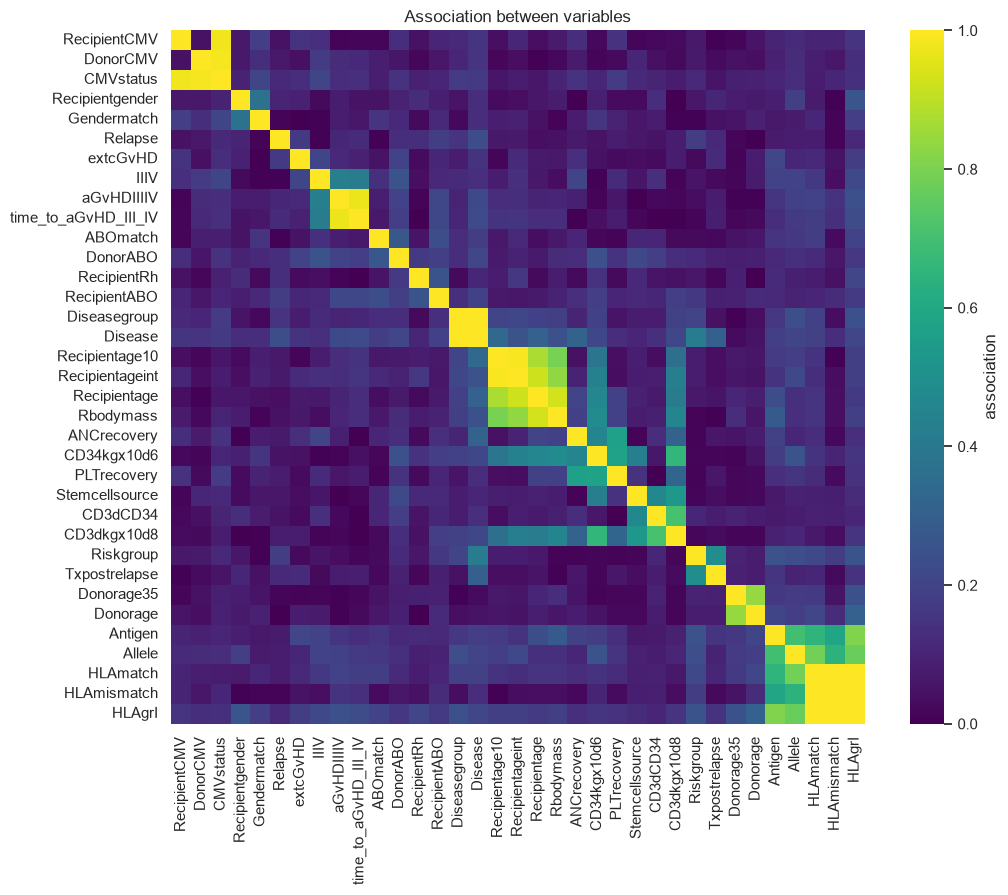

,f1,f2,assoc
350,HLAmismatch,HLAmatch,1.000
327,Diseasegroup,Disease,1.000
506,HLAmatch,HLAgrI,1.000
353,HLAmismatch,HLAgrI,1.000
375,Recipientage10,Recipientageint,0.989
228,DonorCMV,CMVstatus,0.988
254,RecipientCMV,CMVstatus,0.977
423,aGvHDIIIIV,time_to_aGvHD_III_IV,0.969
567,Recipientage,Rbodymass,0.933
551,Recipientageint,Recipientage,0.924


Groups of correlated variables:
   ['DonorCMV', 'CMVstatus']
   ['aGvHDIIIIV', 'time_to_aGvHD_III_IV']
   ['Diseasegroup', 'Disease']
   ['Recipientage10', 'Recipientageint', 'Recipientage', 'Rbodymass']
   ['CD3dCD34', 'CD3dkgx10d8']
   ['Donorage35', 'Donorage']
   ['HLAmismatch', 'HLAmatch', 'Antigen', 'Allele', 'HLAgrI']


In [7]:
def cramers(a, b):
    tab = pd.crosstab(a, b)
    if tab.shape[0] < 2 or tab.shape[1] < 2: return np.nan
    return association(tab.values, method="cramer")

def corr_ratio(cat, num):
    g = num.groupby(cat); tot = ((num - num.mean()) ** 2).sum()
    return np.sqrt(sum(len(x) * (x.mean() - num.mean()) ** 2 for _, x in g) / tot) if tot > 0 else np.nan

def ctype(c): return "num" if c in NUMERIC else "cat"

def assoc(c1, c2):
    # chooses the right measure for each pair of variables
    d = df[[c1, c2]].dropna()
    t1, t2 = ctype(c1), ctype(c2)
    if t1 == "num" and t2 == "num": return abs(spearmanr(d[c1], d[c2])[0])
    if t1 == "cat" and t2 == "cat": return cramers(d[c1], d[c2])
    return corr_ratio(d[c1], d[c2]) if t1 == "cat" else corr_ratio(d[c2], d[c1])

A = pd.DataFrame(np.eye(len(candidates)), index=candidates, columns=candidates)
for i, a in enumerate(candidates):
    for b in candidates[i + 1:]:
        A.loc[a, b] = A.loc[b, a] = assoc(a, b)

# hierarchical clustering to put similar variables together in the heatmap
dist = np.clip(1 - A.fillna(0).values, 0, None); np.fill_diagonal(dist, 0)
Z_link = hierarchy.linkage(squareform(dist, checks=False), method="average")
order = hierarchy.leaves_list(Z_link)

plt.figure(figsize=(11, 9))
sns.heatmap(A.iloc[order, order], cmap="viridis", vmin=0, vmax=1, square=True, cbar_kws={"label": "association"})
plt.title("Association between variables")
plt.tight_layout(); savefig("fig2_association"); plt.show()

pairs = (A.where(np.triu(np.ones(A.shape), 1).astype(bool)).stack().rename("assoc").reset_index()
         .rename(columns={"level_0": "f1", "level_1": "f2"}).sort_values("assoc", ascending=False))
display(pairs.head(15).round(3))

grp = hierarchy.fcluster(Z_link, t=0.4, criterion="distance")
groups_tbl = pd.Series(candidates).groupby(grp).apply(list)
print("Groups of correlated variables:")
for g in groups_tbl:
    if len(g) > 1: print("  ", g)

### 1.4 Choosing the variables

With the previous results we decide which variables we use to describe the patients:

* **Post-transplant variables are removed**, because they are not known at the start and they would leak the outcome.
* **Redundant variables are removed.** Many variables are just another version of one we already have: `Recipientage10` and `Recipientageint` are age groups of `Recipientage`, `HLAmismatch` and `HLAgrI` repeat the HLA information that `HLAmatch` already has, `CD3dCD34` is a ratio of the two doses, `Diseasegroup` is a summary of `Disease`, and `DonorCMV` and `RecipientCMV` are included in `CMVstatus`.
* **Weak variables are removed** (p > 0.2). One problem here is that we select the variables using survival and then we compare survival between the clusters, so it is a bit circular. For this reason in section 3.4 we repeat the analysis without this filter.
* **Age and body mass** are very correlated (about 0.93) but we keep both because they give different information (weight for the age). To avoid counting the same information twice in the clustering, we put them in one **size block**: each one gets a weight of 1/√2, so together they count as one dimension. In the Cox model the ridge penalty helps with this correlation.
* The **cell doses** are very skewed, so we use `log1p` before standardizing. We also merge the rare levels of `Allele` and `Antigen` (less than 10 patients) into a level called "other".

In [8]:
DROP_REDUNDANT = {"Donorage35": "cut of Donorage", "Recipientage10": "cut of Recipientage",
                  "Recipientageint": "cut of Recipientage", "HLAmismatch": "same HLA information as HLAmatch",
                  "HLAgrI": "same HLA information as HLAmatch", "CD3dCD34": "ratio of the two doses",
                  "Diseasegroup": "summary of Disease", "DonorCMV": "included in CMVstatus",
                  "RecipientCMV": "included in CMVstatus"}

features = [c for c in candidates if c not in POST_TX and c not in DROP_REDUNDANT and c not in weak]
size_group = [c for c in SIZE_GROUP if c in features]

# table with the decision for each variable
reason = {}
for c in candidates:
    if c in POST_TX: reason[c] = "removed: post-transplant"
    elif c in DROP_REDUNDANT: reason[c] = "removed: redundant (" + DROP_REDUNDANT[c] + ")"
    elif c in weak: reason[c] = f"removed: weak (p>{P_WEAK})"
    else: reason[c] = "KEPT" + (" (log1p)" if c in LOG_COLS else "") + (" (size block)" if c in size_group else "") \
                      + (" (rare levels merged)" if c in MERGE_RARE_COLS else "")
display(pd.Series(reason, name="decision").to_frame().sort_values("decision"))
print(f"\n{len(features)} variables kept:", features)

,decision
Stemcellsource,KEPT
RecipientRh,KEPT
Disease,KEPT
Riskgroup,KEPT
CD34kgx10d6,KEPT (log1p)
CD3dkgx10d8,KEPT (log1p)
Rbodymass,KEPT (size block)
Recipientage,KEPT (size block)
Relapse,removed: post-transplant
PLTrecovery,removed: post-transplant



8 variables kept: ['Stemcellsource', 'RecipientRh', 'Riskgroup', 'Disease', 'Recipientage', 'Rbodymass', 'CD34kgx10d6', 'CD3dkgx10d8']


## 2. Clustering

The steps before the clustering are: imputation, `log1p` of the doses, standardization of the numeric variables, one-hot encoding of the categorical ones, the weight of the size block (age and body mass) and **PCA** (we keep the components that explain at least 80% of the variance). After that we apply K-means, DBSCAN and GMM.

Design matrix: 11 columns -> 4 principal components (83% of the variance)


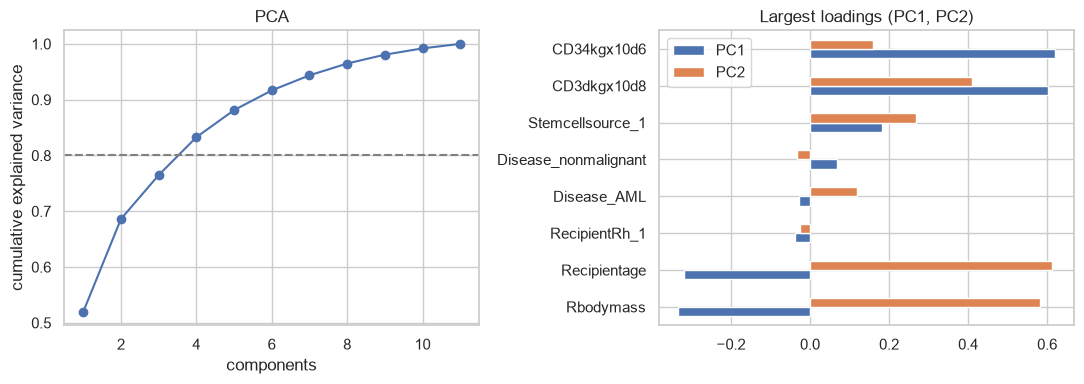

In [9]:
def merge_rare(s, min_count, other="other"):
    vc = s.value_counts(); r = vc[vc < min_count].index
    return s.where(~s.isin(r), other)

def build_design(feats, data):
    d = data[feats].copy()
    for c in feats:
        if c in MERGE_RARE_COLS: d[c] = merge_rare(d[c], MIN_LEVEL)
    num = [c for c in feats if c in NUMERIC]
    log_ = [c for c in num if c in LOG_COLS]; lin = [c for c in num if c not in LOG_COLS]
    bin_ = [c for c in feats if c in BINARY]; cat_ = [c for c in feats if c in CATEGORICAL]
    tr = []
    if lin: tr.append(("num", Pipeline([("i", SimpleImputer(strategy="median")), ("s", StandardScaler())]), lin))
    if log_: tr.append(("log", Pipeline([("i", SimpleImputer(strategy="median")),
                                         ("l", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                         ("s", StandardScaler())]), log_))
    if bin_: tr.append(("bin", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                                         ("o", OneHotEncoder(drop="if_binary", sparse_output=False))]), bin_))
    if cat_: tr.append(("cat", Pipeline([("i", SimpleImputer(strategy="most_frequent")),
                                         ("o", OneHotEncoder(drop="first", sparse_output=False))]), cat_))
    pre = ColumnTransformer(tr)
    M = pre.fit_transform(d)
    names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
    return pd.DataFrame(M, columns=names, index=data.index)

def origin(col, feats):
    """Original variable a design column comes from."""
    for v in sorted(feats, key=len, reverse=True):
        if col == v or col.startswith(v + "_"): return v

def embed(feats, size_weight=True, zscore_all=False, var_target=0.80):
    X = build_design(feats, df)
    if zscore_all:
        Xw = (X - X.mean()) / X.std().replace(0, 1)
    else:
        w = pd.Series(1.0, index=X.columns)
        sg = [c for c in SIZE_GROUP if c in feats]
        if size_weight:
            for c in sg: w[c] = 1 / np.sqrt(len(sg))
        Xw = X * w
    cum = np.cumsum(PCA(random_state=RANDOM_STATE).fit(Xw).explained_variance_ratio_)
    n = int(np.searchsorted(cum, var_target) + 1)
    pca = PCA(n_components=n, random_state=RANDOM_STATE); Z = pca.fit_transform(Xw)
    return dict(X=X, Xw=Xw, Z=Z, pca=pca, cum=cum, n=n)

E = embed(features)
X_df, Z, pca = E["X"], E["Z"], E["pca"]
print(f"Design matrix: {X_df.shape[1]} columns -> {E['n']} principal components "
      f"({E['cum'][E['n']-1]:.0%} of the variance)")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(range(1, len(E["cum"]) + 1), E["cum"], "o-"); ax[0].axhline(0.8, ls="--", c="gray")
ax[0].set_xlabel("components"); ax[0].set_ylabel("cumulative explained variance"); ax[0].set_title("PCA")
load = pd.DataFrame(pca.components_[:2].T, index=X_df.columns, columns=["PC1", "PC2"])
top = load.abs().sum(axis=1).sort_values(ascending=False).head(8).index
load.loc[top].sort_values("PC1").plot.barh(ax=ax[1]); ax[1].set_title("Largest loadings (PC1, PC2)")
plt.tight_layout(); savefig("fig3_pca"); plt.show()

### 2.1 Choosing the number of clusters (K-means)

To choose k we use the **silhouette score**, the **elbow method** (inertia) and the **stability** of the clusters. For the stability we take 30 bootstrap samples (we draw 187 patients with replacement), fit K-means in each sample and compare the result with the clustering of all the patients using the ARI (1 = the same groups, close to 0 = random groups). We also look at the size of the smallest cluster, because we do not want clusters with only a few patients. We do not use survival to choose k, because it would be circular.

,silhouette,inertia,stability_ARI,stability_sd,smallest_cluster
k,,,,,
2,0.336,372.756,0.712,0.165,84
3,0.341,255.957,0.957,0.041,43
4,0.347,214.621,0.794,0.175,20
5,0.273,184.869,0.782,0.118,22
6,0.245,169.009,0.558,0.087,20
7,0.237,155.963,0.534,0.082,20
8,0.230,144.480,0.504,0.109,13


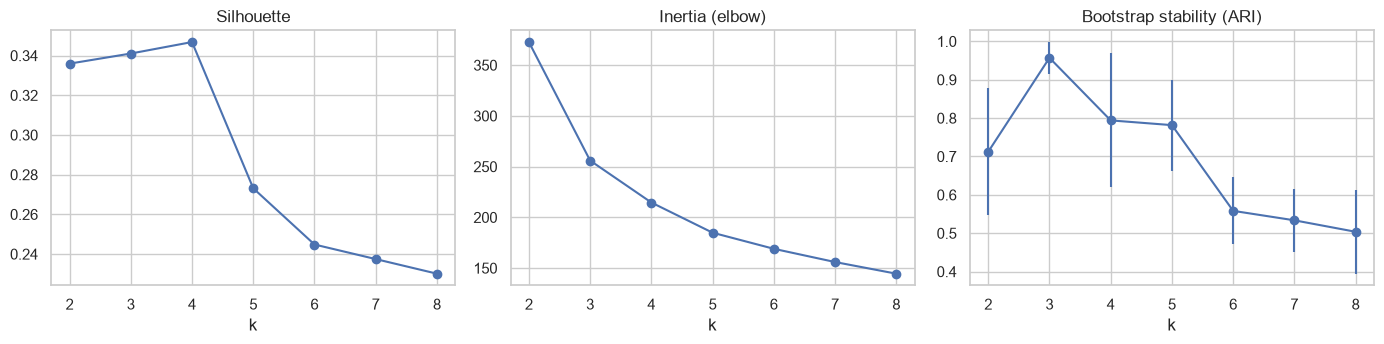

In [10]:
# Stability: how much the clusters change when we use a random sample of the patients (bootstrap)
def stability(Z, k, B=30, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    ref = KMeans(k, n_init=20, random_state=seed).fit(Z).labels_         # clustering with all the patients
    sc = []
    for b in range(B):
        idx = rng.integers(0, len(Z), len(Z))                            # sample with replacement
        km_b = KMeans(k, n_init=10, random_state=b).fit(Z[idx])
        sc.append(adjusted_rand_score(ref, km_b.predict(Z)))             # compare with the clustering of all the patients
    return np.mean(sc), np.std(sc)

rows = []
for k in range(2, 9):
    km_ = KMeans(k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    st_mean, st_sd = stability(Z, k)
    rows.append(dict(k=k, silhouette=silhouette_score(Z, km_.labels_), inertia=km_.inertia_,
                     stability_ARI=st_mean, stability_sd=st_sd, smallest_cluster=np.bincount(km_.labels_).min()))
ksel = pd.DataFrame(rows).set_index("k"); display(ksel.round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ksel.silhouette.plot(marker="o", ax=ax[0], title="Silhouette")
ksel.inertia.plot(marker="o", ax=ax[1], title="Inertia (elbow)")
ax[2].errorbar(ksel.index, ksel.stability_ARI, yerr=ksel.stability_sd, marker="o"); ax[2].set_title("Bootstrap stability (ARI)")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); savefig("fig4_choose_k"); plt.show()

**Choice of k.** We use `K = 3` (it is set at the top of the notebook). The silhouette values are around 0.3, which means the clusters are not very well separated: the patients look more like a continuum, mainly ordered by their size and age (and also by the graft source and the cell doses), than like clearly different groups. Even so, we keep three groups. The silhouette is almost the same for k = 2, 3 and 4 (about 0.34), but k = 3 is clearly the most stable (bootstrap ARI 0.96, against 0.71 for k = 2 and 0.79 for k = 4). Also, the lab asks for groups to compare, three groups allow a simple comparison (one group of young and small patients and two groups of older patients) and the clusters have a reasonable size (see `smallest_cluster`). In section 3.4 we also try other values of k, only as an extra check.

### 2.2 K-means, DBSCAN and GMM

DBSCAN clusters: [np.int64(-1), np.int64(0)] | noise points: 9
ARI K-means vs GMM: 0.78 | K-means vs DBSCAN: 0.01


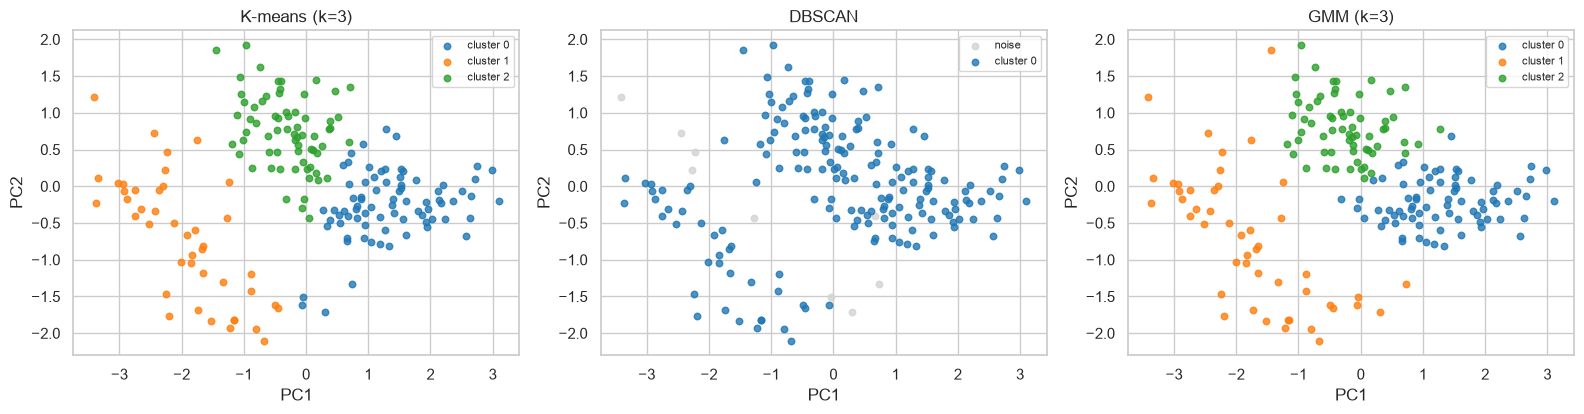

In [11]:
def relabel_by(labels, ref):
    # renames the clusters 0, 1, 2... from smaller to bigger median of ref, so the labels are easy to read
    s = pd.Series(ref.values, index=range(len(labels)))
    med = s.groupby(labels).median().sort_values()
    return np.array([list(med.index).index(l) for l in labels])

size_ref = df["Rbodymass"] if "Rbodymass" in features else df[[c for c in features if c in NUMERIC][0]]

# --- K-means (the one we use) ---
km = KMeans(K, n_init=50, random_state=RANDOM_STATE).fit(Z)
lab_km = relabel_by(km.labels_, size_ref)

# --- DBSCAN: we choose eps from the distance to the 5th neighbour ---
MIN_SAMPLES = 5
kd = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z).kneighbors(Z)[0][:, -1])
eps_db = float(np.percentile(kd, 90))
lab_db = DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES).fit_predict(Z)
print("DBSCAN clusters:", sorted(set(lab_db)), "| noise points:", (lab_db == -1).sum())

# --- GMM ---
gmm = GaussianMixture(K, covariance_type="diag", n_init=10, random_state=RANDOM_STATE).fit(Z)
lab_gmm = relabel_by(gmm.predict(Z), size_ref)
print(f"ARI K-means vs GMM: {adjusted_rand_score(lab_km, lab_gmm):.2f} | "
      f"K-means vs DBSCAN: {adjusted_rand_score(lab_km, lab_db):.2f}")

PAL = sns.color_palette("tab10", 10)
def scatter(ax, lab, title):
    for l in sorted(set(lab)):
        m = lab == l
        ax.scatter(Z[m, 0], Z[m, 1], s=22, alpha=.8, color="lightgray" if l == -1 else PAL[l],
                   label="noise" if l == -1 else f"cluster {l}")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=8)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
scatter(ax[0], lab_km, f"K-means (k={K})"); scatter(ax[1], lab_db, "DBSCAN"); scatter(ax[2], lab_gmm, f"GMM (k={K})")
plt.tight_layout(); savefig("fig5_clusters_pca"); plt.show()

df["cluster"] = lab_km     # these are the clusters we use in the survival analysis

We continue with **K-means** because it is simple and gives a group to every patient. DBSCAN does not work well in this case: the patients form a continuous cloud, so it finds one big cluster and some noise points. We use GMM only as a comparison, and the ARI tells us how similar the groups are to the ones of K-means.

### 2.3 Cluster profiles

The clusters are numbered from the smallest to the biggest median body mass (cluster 0 = smallest patients).

In [12]:
num_used = [c for c in features if c in NUMERIC]; cat_used = [c for c in features if c in BINARY + CATEGORICAL]
print("Cluster sizes:", df.cluster.value_counts().sort_index().to_dict())
display(df.groupby("cluster")[num_used].median().T.round(2).rename_axis("median by cluster"))

prof_cat = pd.concat({c: (pd.crosstab(df[c], df["cluster"], normalize="columns") * 100).round(0) for c in cat_used})
display(prof_cat.rename_axis(["variable", "level"]).rename(columns=lambda c: f"cluster {c} (%)"))

print("\nDisease by cluster (number of patients):")
display(pd.crosstab(df["Disease"], df["cluster"]))
print("Post-transplant events by cluster (% of patients, not used for the clustering):")
post_bin = [c for c in POST_TX if c in BINARY]
display((pd.DataFrame({c: (df[c] == "1").groupby(df.cluster).mean() * 100 for c in post_bin}).T).round(0))

Cluster sizes: {0: 77, 1: 43, 2: 67}


cluster,0,1,2
median by cluster,,,
Recipientage,5.00,12.20,13.80
Rbodymass,18.80,40.30,49.30
CD34kgx10d6,16.46,3.14,8.84
CD3dkgx10d8,6.57,0.40,3.80


cluster                      cluster 0 (%)  cluster 1 (%)  cluster 2 (%)
variable       level                                                    
Stemcellsource 0                       3.0           86.0            4.0
               1                      97.0           14.0           96.0
RecipientRh    0                      21.0            5.0           14.0
               1                      79.0           95.0           86.0
Riskgroup      0                      66.0           56.0           64.0
               1                      34.0           44.0           36.0
Disease        ALL                    32.0           49.0           33.0
               AML                    12.0           16.0           25.0
               chronic                27.0           23.0           21.0
               lymphoma                3.0            7.0            6.0
               nonmalignant           26.0            5.0           15.0


Disease by cluster (number of patients):


cluster,0,1,2
Disease,,,
ALL,25,21,22
AML,9,7,17
chronic,21,10,14
lymphoma,2,3,4
nonmalignant,20,2,10


Post-transplant events by cluster (% of patients, not used for the clustering):


cluster,0,1,2
IIIV,61.0,53.0,63.0
aGvHDIIIIV,75.0,79.0,82.0
extcGvHD,75.0,58.0,67.0
Relapse,14.0,19.0,13.0
Txpostrelapse,9.0,14.0,15.0


## 3. Survival analysis of each cluster

### 3.1 Kaplan-Meier

The Kaplan-Meier estimator gives the survival probability S(t) = P(survive longer than t) of each cluster, with its 95% confidence interval. Under the plot we show the number of patients still at risk at each time. To see if the curves are different we use the **log-rank test**, first for the three clusters together and then for each pair of clusters.

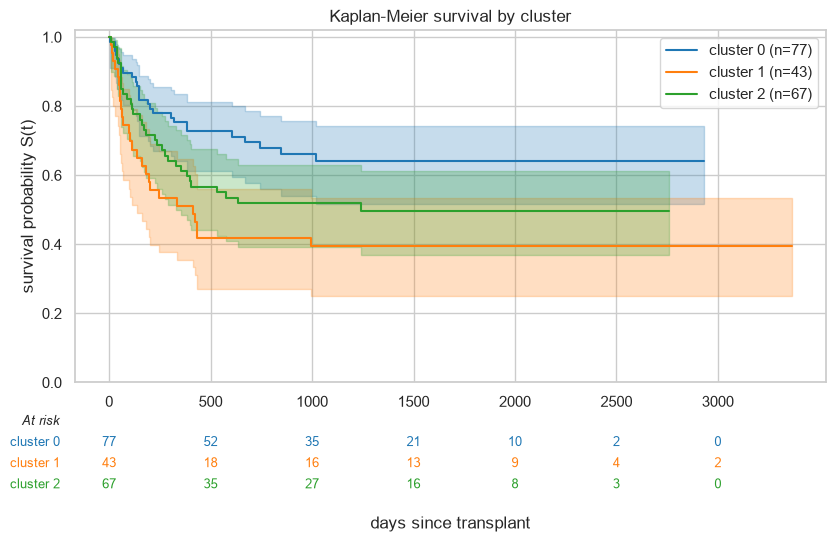

,n,deaths,death rate,median survival (days),S(1 year) [95% CI],S(2 years) [95% CI]
cluster,,,,,,
0,77,26,0.34,not reached,0.75 (0.64-0.83),0.70 (0.58-0.79)
1,43,26,0.60,413,0.51 (0.35-0.65),0.42 (0.27-0.56)
2,67,33,0.49,1243,0.61 (0.48-0.72),0.52 (0.39-0.63)


Global log-rank test: chi2 = 8.91, df = 2, p = 0.0116


test_statistic       p  p adjusted (Bonferroni)
0 1          8.7484  0.0031                   0.0093
  2          3.3160  0.0686                   0.2058
1 2          1.6438  0.1998                   0.5994

In [13]:
clusters = sorted(df.cluster.unique())
km_models = {}
fig, ax = plt.subplots(figsize=(8.5, 6))
for c in clusters:
    sub = df[df.cluster == c]
    m = KaplanMeierFitter(label=f"cluster {c} (n={len(sub)})").fit(sub[TIME], sub[EVENT])
    m.plot_survival_function(ax=ax, ci_show=True, color=PAL[c]); km_models[c] = m
# numbers at risk under the plot (we write them by hand instead of using add_at_risk_counts, which fails with some pandas versions)
ticks = [t for t in ax.get_xticks() if 0 <= t <= df[TIME].max()]
ax.set_xticks(ticks)
for j, c in enumerate(clusters):
    y = -0.17 - 0.06 * j
    ax.text(-0.02, y, f"cluster {c}", transform=ax.transAxes, ha="right", va="center", color=PAL[c], fontsize=9)
    for t in ticks:
        ax.text(t, y, int((df[df.cluster == c][TIME] >= t).sum()), transform=ax.get_xaxis_transform(),
                ha="center", va="center", color=PAL[c], fontsize=9)
ax.text(-0.02, -0.11, "At risk", transform=ax.transAxes, ha="right", va="center", fontsize=9, style="italic")
ax.xaxis.set_label_coords(0.5, -0.38)
ax.set_xlabel("days since transplant"); ax.set_ylabel("survival probability S(t)"); ax.set_ylim(0, 1.02)
ax.set_title("Kaplan-Meier survival by cluster"); plt.tight_layout(); savefig("fig6_km"); plt.show()

def km_at(kmf, t):
    # survival probability at time t with its confidence interval
    if t > kmf.durations.max(): return (np.nan,) * 3
    ci = kmf.confidence_interval_survival_function_; r = ci[ci.index <= t].iloc[-1]
    return float(kmf.predict(t)), float(r.iloc[0]), float(r.iloc[1])
fmt = lambda s: "n/a" if np.isnan(s[0]) else f"{s[0]:.2f} ({s[1]:.2f}-{s[2]:.2f})"

rows = []
for c in clusters:
    sub = df[df.cluster == c]; k = km_models[c]
    med = k.median_survival_time_
    rows.append({"cluster": c, "n": len(sub), "deaths": int(sub[EVENT].sum()),
                 "death rate": round(sub[EVENT].mean(), 2),
                 "median survival (days)": "not reached" if np.isinf(med) else int(med),
                 "S(1 year) [95% CI]": fmt(km_at(k, 365)), "S(2 years) [95% CI]": fmt(km_at(k, 730))})
km_tab = pd.DataFrame(rows).set_index("cluster"); display(km_tab)

# log-rank tests
lr = multivariate_logrank_test(df[TIME], df.cluster, df[EVENT])
print(f"Global log-rank test: chi2 = {lr.test_statistic:.2f}, df = {len(clusters)-1}, p = {lr.p_value:.4f}")
pw = pairwise_logrank_test(df[TIME], df.cluster, df[EVENT]).summary[["test_statistic", "p"]]
pw["p adjusted (Bonferroni)"] = (pw["p"] * len(pw)).clip(upper=1)   # we do 3 comparisons, so we also correct the p-values
display(pw.round(4))

In the table, "not reached" in the median survival means that the estimated curve never goes below 0.5 during the follow-up, so with our data we cannot compute the median survival time.

### 3.2 Cox regression

**(a) Cox with only the cluster.** In this model the only variable is the cluster, and we use the largest cluster as the reference. For each of the other clusters it gives a **hazard ratio (HR)**: an HR below 1 means a lower risk of death than the reference and above 1 means a higher risk. Cox is semi-parametric and assumes that the hazards are proportional over time. We check this assumption with the Schoenfeld test.

In [14]:
ref = df.cluster.value_counts().idxmax()
Dc = pd.get_dummies(df.cluster, prefix="cl", dtype=float).drop(columns=f"cl_{ref}")
Dc_full = pd.concat([Dc, df[[TIME, EVENT]]], axis=1)
cox_c = CoxPHFitter().fit(Dc_full, TIME, EVENT)
print(f"Reference cluster: {ref}")
display(cox_c.summary[["coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3))
print(f"Concordance (train): {cox_c.concordance_index_:.3f}")

ph_c = proportional_hazard_test(cox_c, Dc_full, time_transform="rank").summary
print("\nProportional hazards test (Schoenfeld):"); display(ph_c.round(3))

Reference cluster: 0


,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,,
cl_1,0.808,2.244,1.302,3.867,0.004
cl_2,0.474,1.606,0.960,2.686,0.071


Concordance (train): 0.591

Proportional hazards test (Schoenfeld):


,test_statistic,p,-log2(p)
cl_1,0.302,0.583,0.779
cl_2,0.010,0.921,0.119


With only about 80 deaths this test does not have much power, so a high p-value only means that we do not find evidence against proportional hazards, it does not prove it. If the Kaplan-Meier curves cross, it would be a warning sign.

**(b) Cox with all the patient variables.** Now the model uses the variables of each patient and not only the cluster. With this we can (1) get a survival curve for each cluster, averaging the predicted curves of its patients, and (2) see which variables are more important for the risk through the hazard ratios.

We only have about 85 deaths and more than 10 columns in the design matrix, so a normal Cox model could overfit. To control this we add a **ridge penalty** and we choose its value with **cross-validation**: for each value we compute the C-index in 5-fold cross-validation (repeated 3 times) and we take the largest penalty whose result is within one standard error of the best one. We keep **two fits** of the same model:

* the fit with the penalty chosen by cross-validation (`PEN`), that we use to measure the predictive performance and to draw the curves;
* a fit with a small penalty (`PEN_INTERP = 0.1`), that we use to read the hazard ratios, because a big penalty pushes all the coefficients towards 0 and hides the effects.

The variables are standardized, so the HR of a numeric variable is for an increase of 1 standard deviation, and the HR of a dummy variable is compared with its reference level.

,mean C,SE
0.01,0.586,0.016
0.03,0.590,0.016
0.10,0.594,0.016
0.30,0.604,0.017
1.00,0.608,0.018
3.00,0.614,0.018
10.00,0.616,0.018
30.00,0.616,0.018


Best penalty: 30.0 | selected with the 1-SE rule: 30.0
The selected penalty is the biggest one of the grid, so the model is strongly shrunk. Its hazard ratios are very close to 1, so we read the effects from the fit with the small penalty.
CV C-index | only cluster: 0.591 | all variables (ridge 30.0): 0.616 | all variables (ridge 0.1): 0.594
Train C-index (optimistic) | ridge 30.0: 0.641 | ridge 0.1: 0.651


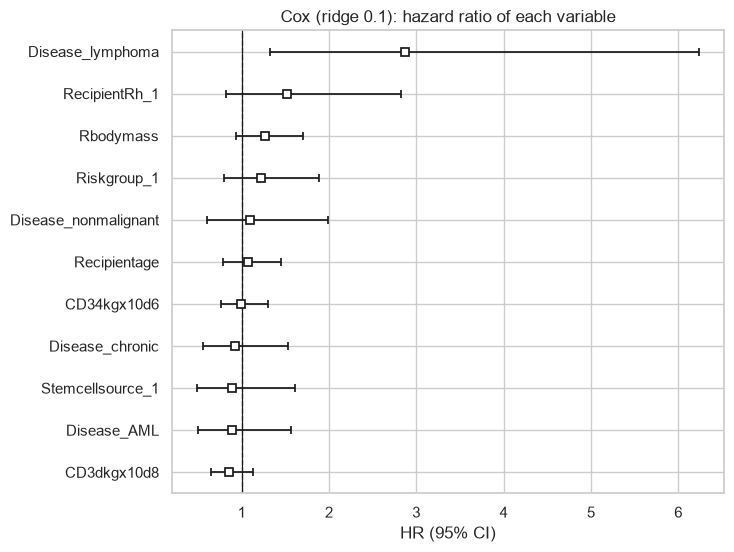

ridge 0.1                                                 \
                     exp(coef) exp(coef) lower 95% exp(coef) upper 95%      p   
covariate                                                                       
Disease_lymphoma         2.871               1.322               6.236  0.008   
Rbodymass                1.262               0.936               1.701  0.127   
RecipientRh_1            1.521               0.819               2.825  0.184   
CD3dkgx10d8              0.858               0.655               1.126  0.269   
Riskgroup_1              1.226               0.797               1.887  0.354   
Recipientage             1.072               0.791               1.452  0.653   
Disease_AML              0.888               0.502               1.570  0.683   
Stemcellsource_1         0.891               0.492               1.614  0.704   
Disease_chronic          0.926               0.562               1.527  0.763   
Disease_nonmalignant     1.090               0.598               1.988  0.777   
CD34kgx10d6              0.998               0.769               1.297  0.990   

                     ridge 30.0 (CV)  
                           exp(coef)  
covariate                             
Disease_lymphoma               1.025  
Rbodymass                      1.005  
RecipientRh_1                  1.009  
CD3dkgx10d8                    0.995  
Riskgroup_1                    1.006  
Recipientage                   1.005  
Disease_AML                    1.000  
Stemcellsource_1               0.993  
Disease_chronic                0.998  
Disease_nonmalignant           0.997  
CD34kgx10d6                    0.996

In [15]:
Dx = X_df.loc[:, X_df.std() > 0].copy(); cols = list(Dx.columns)
Dx[TIME], Dx[EVENT] = df[TIME].values, df[EVENT].values

def cv_cindex(data, covs, pen, n_rep=3, k=5):
    # C-index in cross-validation (it is more honest than the train C-index)
    sc = []
    for r in range(n_rep):
        for tr, te in StratifiedKFold(k, shuffle=True, random_state=RANDOM_STATE + r).split(data, data[EVENT]):
            try:
                m = CoxPHFitter(penalizer=pen).fit(data.iloc[tr][covs + [TIME, EVENT]], TIME, EVENT)
                sc.append(m.score(data.iloc[te][covs + [TIME, EVENT]], scoring_method="concordance_index"))
            except Exception:
                sc.append(np.nan)
    return np.array(sc)

# we try several penalties and choose one with the "1 standard error" rule
pens = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]
cv_res = {p: cv_cindex(Dx, cols, p) for p in pens}
cvt = pd.DataFrame({"mean C": {p: np.nanmean(v) for p, v in cv_res.items()},
                    "SE": {p: np.nanstd(v) / np.sqrt(np.isfinite(v).sum()) for p, v in cv_res.items()}})
display(cvt.round(3))
best = cvt["mean C"].idxmax()
PEN = max(p for p in pens if cvt.loc[p, "mean C"] >= cvt.loc[best, "mean C"] - cvt.loc[best, "SE"])
print(f"Best penalty: {best} | selected with the 1-SE rule: {PEN}")
if PEN == max(pens):
    print("The selected penalty is the biggest one of the grid, so the model is strongly shrunk. "
          "Its hazard ratios are very close to 1, so we read the effects from the fit with the small penalty.")
PEN_INTERP = 0.1   # small penalty used to read the hazard ratios

cox_f = CoxPHFitter(penalizer=PEN).fit(Dx, TIME, EVENT)            # penalty chosen by CV: performance and curves
cox_i = CoxPHFitter(penalizer=PEN_INTERP).fit(Dx, TIME, EVENT)     # small penalty: hazard ratios
cv_full = cv_cindex(Dx, cols, PEN); cv_int = cv_cindex(Dx, cols, PEN_INTERP)
cv_clu = cv_cindex(Dc_full, list(Dc.columns), 0.0)
print(f"CV C-index | only cluster: {np.nanmean(cv_clu):.3f} | all variables (ridge {PEN}): {np.nanmean(cv_full):.3f} "
      f"| all variables (ridge {PEN_INTERP}): {np.nanmean(cv_int):.3f}")
print(f"Train C-index (optimistic) | ridge {PEN}: {cox_f.concordance_index_:.3f} | ridge {PEN_INTERP}: {cox_i.concordance_index_:.3f}")

plt.figure(figsize=(7.5, 0.38 * len(cols) + 1.5))
cox_i.plot(hazard_ratios=True); plt.axvline(1, c="k", lw=.8)
plt.title(f"Cox (ridge {PEN_INTERP}): hazard ratio of each variable")
plt.tight_layout(); savefig("fig7_cox_forest"); plt.show()

hr_tab = pd.concat({f"ridge {PEN_INTERP}": cox_i.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]],
                    f"ridge {PEN} (CV)": cox_f.summary[["exp(coef)"]]}, axis=1)
display(hr_tab.sort_values((f"ridge {PEN_INTERP}", "p")).round(3))

Because of the ridge penalty the confidence intervals and p-values are only approximate, so we use them to see the direction of the effects and to rank the variables, but not as a formal test.

**Importance of each variable.** A categorical variable is split into several dummy columns, so the importance of one dummy is not the importance of the whole variable. To compare variables we add the absolute value of the coefficients (fit with the small penalty) of all the columns that come from the same original variable. A bigger value means that the variable has more effect on the risk (all the columns are standardized or 0/1, so they are on a similar scale). This is only a guide: a variable with many dummy columns (like `Disease`) adds more terms, so it can look more important just because of that. For this reason we also look at the hazard ratios.

,variable,n_columns,sum |coef|
0,Disease,4,1.337
1,RecipientRh,1,0.420
2,Rbodymass,1,0.233
3,Riskgroup,1,0.204
4,CD3dkgx10d8,1,0.153
5,Stemcellsource,1,0.115
6,Recipientage,1,0.070
7,CD34kgx10d6,1,0.002


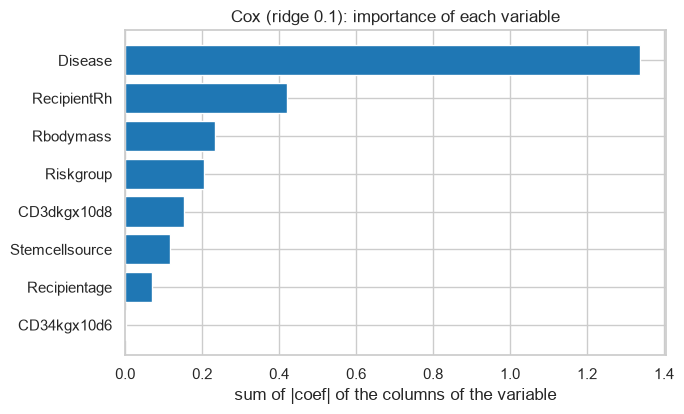

In [16]:
var_of = {c: origin(c, features) for c in cols}
imp = pd.DataFrame({"variable": [var_of[c] for c in cols], "abs_coef": cox_i.params_[cols].abs().values})
imp = (imp.groupby("variable").agg(n_columns=("abs_coef", "size"), sum_abs_coef=("abs_coef", "sum"))
          .sort_values("sum_abs_coef", ascending=False).reset_index())
imp = imp.rename(columns={"sum_abs_coef": "sum |coef|"})
display(imp.round(3))

fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1.5))
ax.barh(imp["variable"][::-1], imp["sum |coef|"][::-1], color="tab:blue")
ax.set_xlabel("sum of |coef| of the columns of the variable"); ax.set_title(f"Cox (ridge {PEN_INTERP}): importance of each variable")
plt.tight_layout(); savefig("fig8_cox_importance"); plt.show()

### 3.3 Kaplan-Meier vs Cox in each cluster

* **Kaplan-Meier** does not make assumptions about the shape of the curve, but it only knows the cluster of the patient.
* **Cox with only the cluster** uses the same information, so its curve should be a smoother version of the Kaplan-Meier curve. If they are very different, the proportional hazards assumption may not hold.
* **Cox with all the variables** gives one curve for each patient, and the curve of a cluster is the average of the curves of its patients. It uses more information, so it can be different from Kaplan-Meier when a cluster has both high-risk and low-risk patients. We draw it with the two penalties: the stronger the penalty, the flatter the curves. Both are evaluated on the same data used to train them, so we have to be careful.

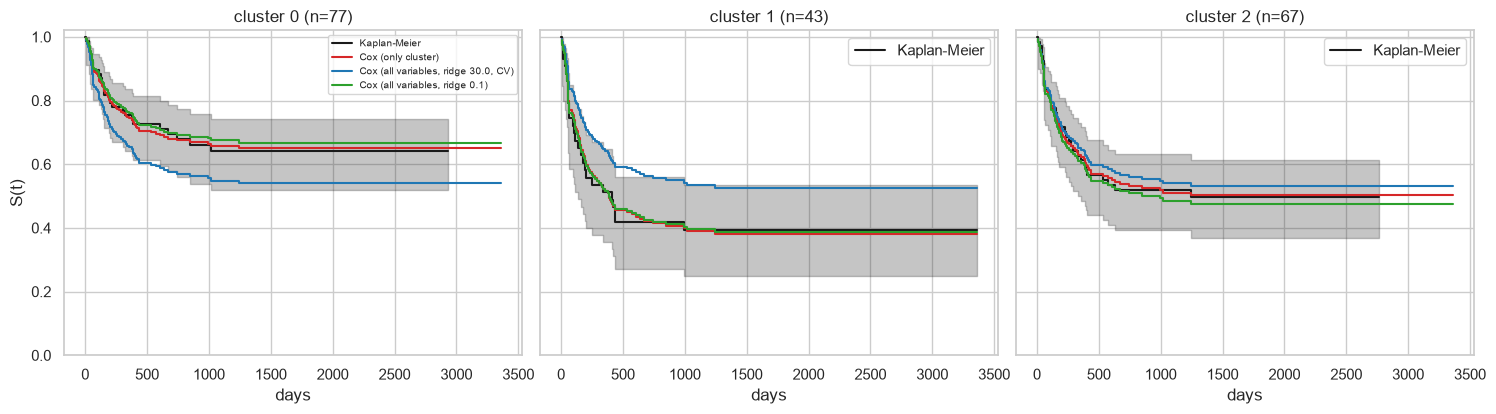

,mean |KM - Cox(cluster)|,"mean |KM - Cox(features, CV ridge)|","mean |KM - Cox(features, ridge 0.1)|"
cluster,,,
0,0.011,0.088,0.018
1,0.016,0.124,0.013
2,0.009,0.027,0.019


,mean partial hazard (ridge 30.0),mean partial hazard (ridge 0.1),S(1y) KM
0,0.982,0.688,0.753
1,1.022,1.912,0.512
2,1.006,1.293,0.612


In [17]:
Xcox = Dx.drop(columns=[TIME, EVENT])
sf_feat = cox_f.predict_survival_function(Xcox); sf_int = cox_i.predict_survival_function(Xcox)
cl_covs = list(Dc.columns)

def gap_vs_km(c, sf):
    # mean absolute difference between the Kaplan-Meier curve and a Cox curve
    k = km_models[c]; t = sf.index.values; t = t[t <= k.durations.max()]
    return float(np.mean(np.abs(k.predict(t).values - sf.loc[t].values)))

fig, ax = plt.subplots(1, len(clusters), figsize=(5 * len(clusters), 4.3), sharey=True)
gaps = []
for a, c in zip(np.atleast_1d(ax), clusters):
    km_models[c].plot_survival_function(ax=a, ci_show=True, color="k", label="Kaplan-Meier")
    # Cox with only the cluster
    row = pd.DataFrame(0.0, index=[0], columns=cl_covs)
    if f"cl_{c}" in cl_covs: row[f"cl_{c}"] = 1.0
    sf_c = cox_c.predict_survival_function(row).iloc[:, 0]
    # Cox with all the variables: average of the curves of the patients of the cluster
    sf_f = sf_feat.loc[:, df.index[df.cluster == c]].mean(axis=1)
    sf_i = sf_int.loc[:, df.index[df.cluster == c]].mean(axis=1)
    a.step(sf_c.index, sf_c.values, where="post", color="tab:red", label="Cox (only cluster)")
    a.step(sf_f.index, sf_f.values, where="post", color="tab:blue", label=f"Cox (all variables, ridge {PEN}, CV)")
    a.step(sf_i.index, sf_i.values, where="post", color="tab:green", label=f"Cox (all variables, ridge {PEN_INTERP})")
    a.set_title(f"cluster {c} (n={(df.cluster == c).sum()})"); a.set_xlabel("days"); a.set_ylim(0, 1.02)
    gaps.append({"cluster": c, "mean |KM - Cox(cluster)|": gap_vs_km(c, sf_c),
                 "mean |KM - Cox(features, CV ridge)|": gap_vs_km(c, sf_f),
                 f"mean |KM - Cox(features, ridge {PEN_INTERP})|": gap_vs_km(c, sf_i)})
np.atleast_1d(ax)[0].set_ylabel("S(t)"); np.atleast_1d(ax)[0].legend(fontsize=7)
plt.tight_layout(); savefig("fig9_km_vs_cox"); plt.show()
gap_tab = pd.DataFrame(gaps).set_index("cluster"); display(gap_tab.round(3))

# does the risk of the Cox model with all the variables follow the order of Kaplan-Meier?
risk = pd.DataFrame({f"mean partial hazard (ridge {PEN})": cox_f.predict_partial_hazard(Xcox).groupby(df.cluster).mean(),
                     f"mean partial hazard (ridge {PEN_INTERP})": cox_i.predict_partial_hazard(Xcox).groupby(df.cluster).mean(),
                     "S(1y) KM": [km_at(km_models[c], 365)[0] for c in clusters]}, index=clusters)
display(risk.round(3))

### 3.4 Extra checks

To see if our conclusions depend too much on our decisions we repeat the clustering changing some things: (a) other values of k and (b) using also the weak variables (without the filter by survival, which removes the circularity problem we mentioned in section 1.4). For each case we show the ARI compared with our main clustering and the p-value of the global log-rank test. We do not use these results to choose k, only to check how stable the results are.

In [18]:
def logrank_p(lab): return multivariate_logrank_test(df[TIME], lab, df[EVENT]).p_value

sens = []
for k in [k for k in [2, 3, 4] if k != K]:
    lab = KMeans(k, n_init=50, random_state=RANDOM_STATE).fit_predict(Z)
    sens.append({"analysis": f"K-means with k={k}", "ARI vs main": adjusted_rand_score(lab_km, lab), "log-rank p": logrank_p(lab)})

# (b) all the baseline variables, without removing the weak ones
feats_nofilter = [c for c in candidates if c not in POST_TX and c not in DROP_REDUNDANT]
lab_nf = KMeans(K, n_init=50, random_state=RANDOM_STATE).fit_predict(embed(feats_nofilter)["Z"])
sens.append({"analysis": f"without the weak-variable filter ({len(feats_nofilter)} variables)",
             "ARI vs main": adjusted_rand_score(lab_km, lab_nf), "log-rank p": logrank_p(lab_nf)})
sens.append({"analysis": f"main analysis (K-means k={K})", "ARI vs main": 1.0, "log-rank p": lr.p_value})
sens_tab = pd.DataFrame(sens).set_index("analysis"); display(sens_tab.round(4))

,ARI vs main,log-rank p
analysis,,
K-means with k=2,0.4453,0.0074
K-means with k=4,0.8914,0.0001
without the weak-variable filter (18 variables),0.9502,0.0064
main analysis (K-means k=3),1.0000,0.0116


### 3.5 Summary of the results

In [19]:
# quick summary of the main numbers (it is updated automatically if we change something above)
print("Cluster sizes:", df.cluster.value_counts().sort_index().to_dict())
print(f"Global log-rank p-value: {lr.p_value:.4f} ->",
      "there is evidence that the survival curves are different" if lr.p_value < 0.05
      else "no clear evidence of a difference between the curves")
print("\nSurvival at 1 year (Kaplan-Meier):")
for c in clusters:
    print(f"  cluster {c}: {fmt(km_at(km_models[c], 365))}")
print(f"\nHazard ratios of the Cox model with the cluster (reference = cluster {ref}):")
display(cox_c.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3))
print(f"CV C-index: only cluster = {np.nanmean(cv_clu):.3f} | all variables (ridge {PEN}) = {np.nanmean(cv_full):.3f} | all variables (ridge {PEN_INTERP}) = {np.nanmean(cv_int):.3f}")
print("\nThree variables with the largest sum of |coef| in the Cox model (only a guide, see section 3.2):", list(imp["variable"].head(3)))

Cluster sizes: {0: 77, 1: 43, 2: 67}
Global log-rank p-value: 0.0116 -> there is evidence that the survival curves are different

Survival at 1 year (Kaplan-Meier):
  cluster 0: 0.75 (0.64-0.83)
  cluster 1: 0.51 (0.35-0.65)
  cluster 2: 0.61 (0.48-0.72)

Hazard ratios of the Cox model with the cluster (reference = cluster 0):


,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
cl_1,2.244,1.302,3.867,0.004
cl_2,1.606,0.960,2.686,0.071


CV C-index: only cluster = 0.591 | all variables (ridge 30.0) = 0.616 | all variables (ridge 0.1) = 0.594

Three variables with the largest sum of |coef| in the Cox model (only a guide, see section 3.2): ['Disease', 'RecipientRh', 'Rbodymass']


### 3.6 Kaplan-Meier vs Cox regression

| | Kaplan-Meier | Cox regression |
|---|---|---|
| Type | Non-parametric | Semi-parametric (proportional hazards) |
| Output | Survival curve S(t) of each group | Hazard ratios of each variable, S(t) for a patient or a group |
| Variables | Only the group | Any number of variables |
| Assumptions | Censoring does not depend on the outcome | The same + proportional hazards |
| Interpretation | Very direct (curves, median, S(1 year)) | The HR of each variable shows its importance |
| Problems here | Wide intervals in small clusters | Overfitting (few deaths), correlated variables, approximate p-values with the penalty |

### Conclusions

**1. Which groups did we find?** K-means with k = 3 gives three groups that differ in the size of the patient, the type of graft and the cell dose. Cluster 0 (77 patients) are the youngest and smallest (median age 5 years and 19 kg), they received high doses of CD34 and CD3 cells and almost all of them (97%) have a peripheral blood graft. Cluster 1 (43 patients) are older and heavier (12 years, 40 kg), they received very low doses (median CD34 = 3.1 and CD3 = 0.4) and 86% of them have a bone marrow graft. Cluster 2 (67 patients) are the oldest and the biggest (14 years, 49 kg), with intermediate doses and mostly peripheral blood. Clusters 1 and 2 have a similar size, so what separates them is mainly the graft source and the cell dose. The silhouette for k = 3 is only about 0.34, so the groups are not clearly separated. Even so, k = 3 is the most stable choice (bootstrap ARI 0.96).

**2. Do the clusters have different survival?** Yes, the global log-rank test gives chi2 = 8.91 and p = 0.012.

| Cluster | Patients | Deaths | Median survival | Alive at 1 year | Alive at 2 years |
|---|---|---|---|---|---|
| 0 | 77 | 26 (34%) | Not reached | 75% | 70% |
| 1 | 43 | 26 (60%) | 413 days | 51% | 42% |
| 2 | 67 | 33 (49%) | 1243 days | 61% | 52% |

Cluster 0 has the best survival and cluster 1 the worst. In the pairs, only cluster 0 vs cluster 1 is clearly different (p = 0.003, or 0.009 after the Bonferroni correction for the three comparisons). Cluster 0 vs cluster 2 has p = 0.069 (0.21 corrected), so we do not see a clear difference, and cluster 1 vs cluster 2 is not significant (p = 0.20, corrected 0.60). The Cox model with only the cluster says the same (reference = cluster 0): cluster 1 has an HR of 2.24 (95% CI 1.30-3.87, p = 0.004), so its risk of death is about double (the interval starts at 1.30, so we cannot be sure that it is more than double), and cluster 2 has an HR of 1.61 (95% CI 0.96-2.69, p = 0.071), which is higher but the interval includes 1. The Schoenfeld test does not show evidence against proportional hazards (p = 0.58 and 0.92).

**3. Do Kaplan-Meier and Cox agree?** The Cox model with only the cluster is almost on top of the Kaplan-Meier curves (mean difference between 0.009 and 0.016), which is expected because both use the same information. The Cox model with all the variables depends a lot on the penalty. With the penalty chosen by cross-validation (ridge 30) the curves are much flatter (differences of 0.09, 0.12 and 0.03) and the mean risk of the three clusters is almost the same (between 0.98 and 1.02), so this model does not separate the clusters in the size of the risk. But the penalty only squeezes all the risks towards 1 and keeps the order of the patients: this model has the best cross-validated C-index (0.62), so it still ranks the patients as well as the other two (the three C-index values are within the noise). With the small penalty (ridge 0.1) the curves are close to Kaplan-Meier (differences of about 0.02) and the order of the risk is the same: mean risk of 0.69 for cluster 0, 1.29 for cluster 2 and 1.91 for cluster 1.

**4. Which variables are the most important?** Using the model with the small penalty, the only clear effect is the lymphoma, with an HR of 2.87 (95% CI 1.32-6.24, p = 0.008). However, there are only 9 patients with lymphoma, so this result is not very stable. The other variables have intervals that include 1: body mass (HR = 1.26 per standard deviation, p = 0.13) and Rh positive (HR = 1.52, p = 0.18) are the next ones. In the importance table `Disease` is the first (sum of |coef| = 1.34, mostly because of the lymphoma, but also because it has four columns), followed by `RecipientRh` (0.42) and `Rbodymass` (0.23). The cell doses, the age and the graft source have small effects. The predictive power is low: the cross-validated C-index is 0.59 for the model with only the cluster, 0.62 with ridge 30 and 0.59 with ridge 0.1. The train values (0.64 and 0.65) are higher, but they are optimistic. This means that the baseline variables alone do not predict the survival of a single patient very well.

**5. Are the results stable?** With k = 4 the clusters are very similar to the ones of k = 3 (ARI = 0.89) and the survival is also different (p = 0.0001). With k = 2 the groups change more (ARI = 0.45) but the test is still significant (p = 0.007). If we do not remove the weak variables (18 variables), the clusters are almost the same (ARI = 0.95) and the log-rank p-value is 0.006, so the result does not depend on this filter. We use these checks only as a comparison, not to choose k.

**Final conclusion.** The group of older and heavier patients that received low cell doses, mostly from bone marrow (cluster 1), has the worst survival, and the youngest and smallest patients (cluster 0) have the best. The difference between these two groups is clear, and the intermediate group is in the middle. However, the clusters are different in many variables at the same time (age, body mass, cell doses, graft source and disease), so we cannot say which of them causes the difference in survival.

### Limitations

* The sample is small (187 patients and about 85 deaths), so the confidence intervals are wide and the tests do not have much power.
* The cluster structure is weak (silhouette around 0.34). The clusters are mostly a division of a continuous variation in the size and age of the patients, in the cell doses and in the graft source.
* We removed the weak variables using survival, which is a bit circular (see section 3.4).
* The cross-validated C-index is probably a bit optimistic: the weak variables were removed with a univariate Cox model using all the patients, the preprocessing was done before the folds and the penalty was chosen with the same cross-validation. We did not repeat these steps inside each fold.
* The clusters differ in age, disease, graft source and cell dose at the same time, so we cannot say that the difference in survival is caused by only one of them. The Cox model only adjusts for the variables we have.
* We do three comparisons between pairs of clusters, so we show the p-values with and without the Bonferroni correction. Only the pair 0 vs 1 stays significant after the correction.
* We did not use the post-transplant variables, even if they are strongly related to survival, because they are not known at the start.
* With the ridge penalty the p-values and the intervals of the Cox model are approximate, and the effect of the lymphoma is based on only 9 patients.

## 4. Export for the report

In [20]:
out = km_tab.join(pd.DataFrame({"HR vs ref (Cox, cluster)": [1.0 if c == ref else cox_c.summary.loc[f"cl_{c}", "exp(coef)"] for c in clusters]}, index=clusters))
out.to_csv("results_clusters.csv"); imp.to_csv("results_cox_importance.csv", index=False)
sens_tab.to_csv("results_sensitivity.csv")
print("Tables saved: results_clusters.csv, results_cox_importance.csv, results_sensitivity.csv")
print("Figures saved in", FIG_DIR.resolve())
for p in sorted(FIG_DIR.glob("*.png")):
    print("  ", p.name)

Tables saved: results_clusters.csv, results_cox_importance.csv, results_sensitivity.csv
Figures saved in /Users/macbook/Downloads/LAB2-Health_ML/figures
   fig1_univariate.png
   fig2_association.png
   fig3_pca.png
   fig4_choose_k.png
   fig5_clusters_pca.png
   fig6_km.png
   fig7_cox_forest.png
   fig8_cox_importance.png
   fig9_km_vs_cox.png


For the 2-page report we plan to use 4 or 5 small figures: `fig1_univariate` or `fig2_association` (exploratory analysis), `fig5_clusters_pca` (clusters), `fig6_km` (survival), `fig9_km_vs_cox` (comparison of the methods) and `fig7_cox_forest` or `fig8_cox_importance` (interpretation). We also have to add the names of all the team members at the top and the link to the code (Drive/GitHub).